Step 1: Split the received signal as ref signal \& loc signal. Get the basic information including sample rate, starting time, etc.

The ref signal ends at index 44200000


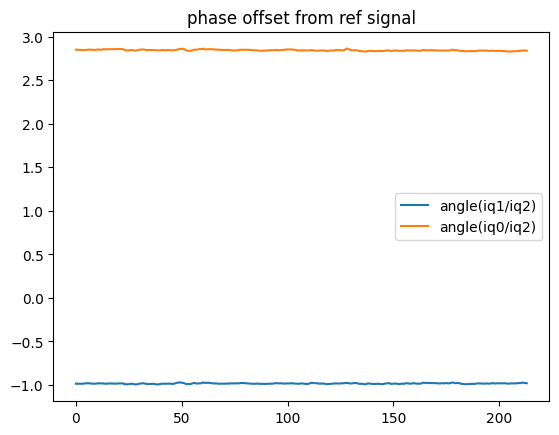

In [1]:
from preproc import preproc
import os
import scipy.io as sio
iq0_path = '/home/ishani/LeoPNT/USRP_data/12_27/time_20_47_freq_11_325G_bw_2.0M_1703724657.2378652_inrx0.dat'
sample_rate = 2e6
date = "12_27"
start_time = 1703724657.2378652
loc_sig_idx = preproc(iq0_path, sample_rate)

if not os.path.exists(date):
    os.makedirs(date)
# save sample_rate, date, start_time, loc_sig_idx to .mat file
sio.savemat(date + '/info.mat', {'IQ_Sample_file_0': iq0_path,'sample_rate': sample_rate, 'date': date, 'start_time': start_time, 'loc_sig_idx': loc_sig_idx})


Step 2: do the central tone tracking using matlab

In [ ]:
# matlab
# cd Starloc/
# center_tone_track
# results saved to $date/peaks.mat

Step 3: use the tracked central tones to identify the satellite's ID

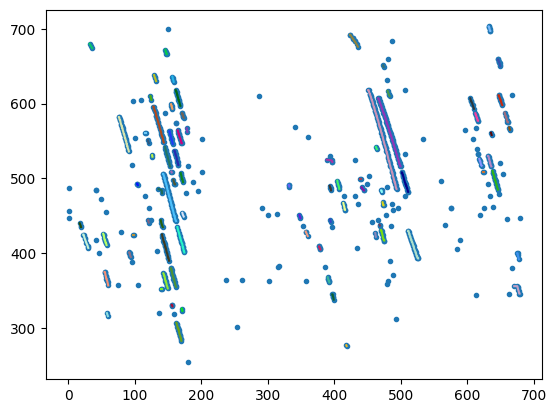

In [2]:
from sat_id import connect_doppler
track_dict = connect_doppler(date)
output_tracks_file = date+"/output_tracks.mat"
sio.savemat(output_tracks_file, {'tracks_dict': track_dict})